# Building Energy Prediction: A Hands-On Guide

## 1. Setup and Imports
First, we'll import the necessary libraries and set a random seed for reproducibility.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
import shap

# Set plot style
sns.set_style("whitegrid")

# Seed for reproducibility
np.random.seed(42)

## 2. Load Data
Next, we load our synthetic dataset. We'll parse the timestamps and set them as the index.

In [2]:
df = pd.read_csv('building_data.csv', parse_dates=['timestamp'], index_col='timestamp')
print("Data loaded successfully!")
df.head()

Data loaded successfully!


,energy_kwh,temperature,humidity
timestamp,,,
2023-01-01 00:00:00,96.775844,2.213827,90.429407
2023-01-01 01:00:00,104.976086,1.114241,81.295224
2023-01-01 02:00:00,85.042839,3.185649,77.690936
2023-01-01 03:00:00,105.493308,5.730925,81.432699
2023-01-01 04:00:00,73.024146,3.252092,83.174127


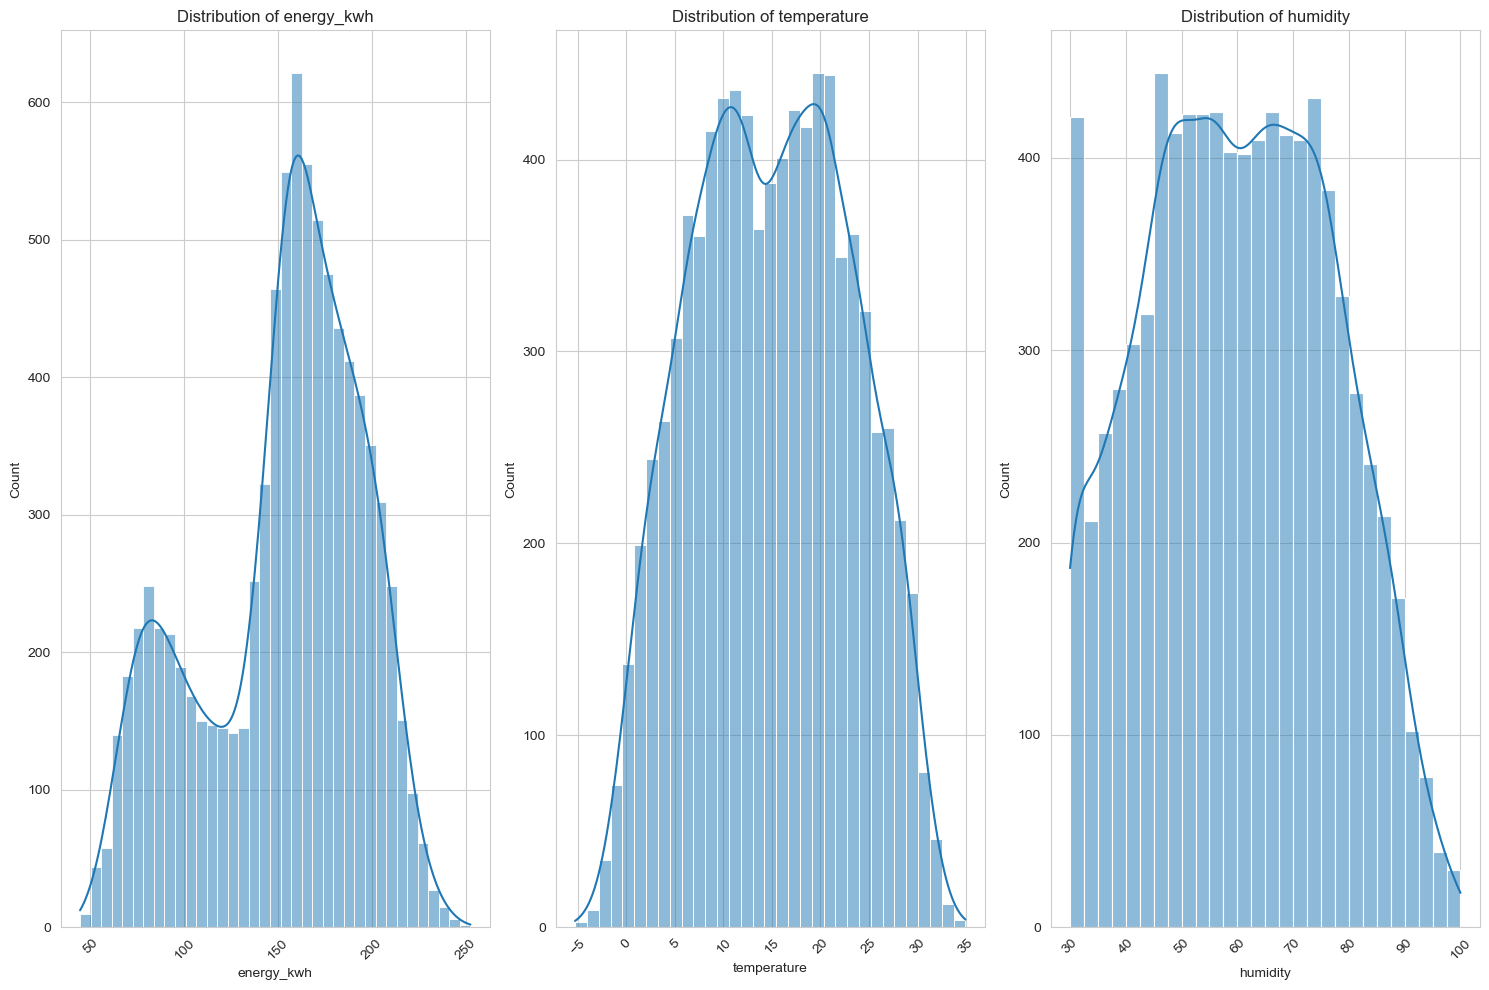

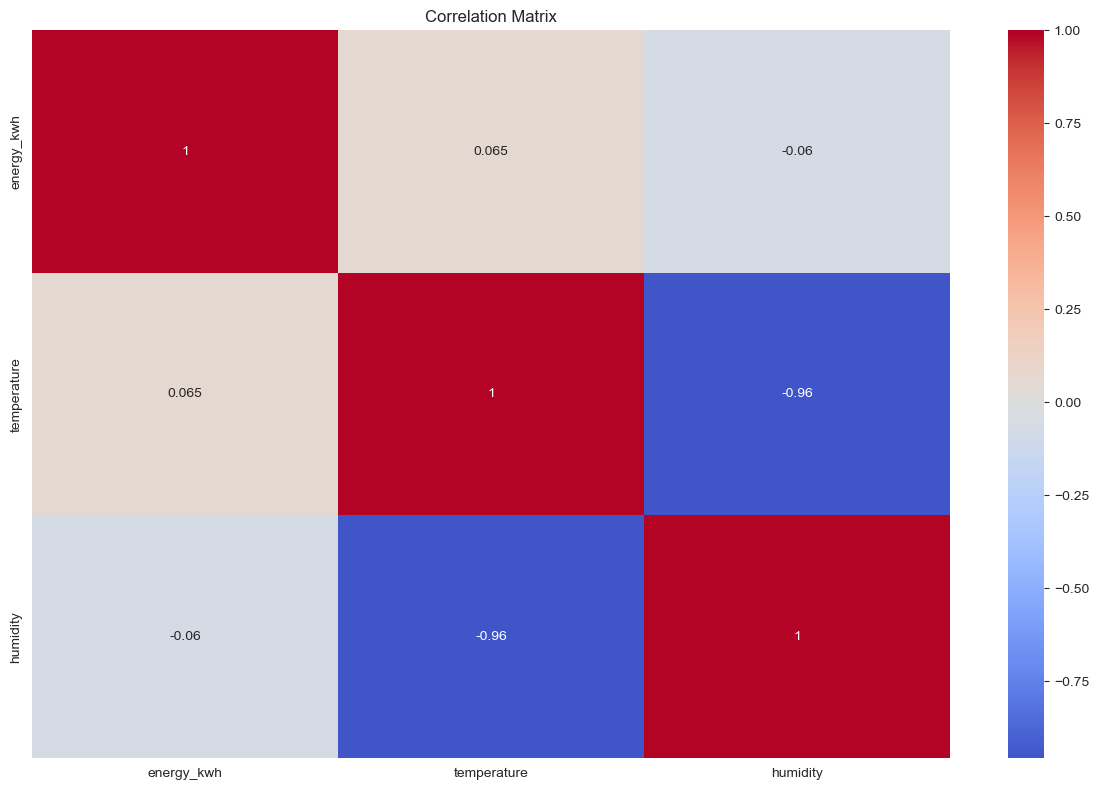


Dataset Statistics:
        energy_kwh  temperature     humidity
count  8672.000000  8672.000000  8672.000000
mean    152.316461    14.991904    60.183355
std      42.763038     8.104746    16.668374
min      44.504607    -5.282539    30.000000
25%     124.919635     8.618674    47.104057
50%     159.845451    15.028256    60.076223
75%     183.898438    21.288679    73.205358
max     252.571566    34.934670   100.000000

Missing Values:
energy_kwh     88
temperature    88
humidity       88
dtype: int64


In [3]:
# Visualize all columns in the dataframe
import matplotlib.pyplot as plt
import seaborn as sns

# Set figure size
plt.figure(figsize=(15, 10))

# Create subplots for each numeric column
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
n_cols = len(numeric_cols)
n_rows = (n_cols + 2) // 3  # Calculate number of rows needed (3 plots per row)

for i, col in enumerate(numeric_cols, 1):
    plt.subplot(n_rows, 3, i)
    sns.histplot(data=df, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# Create correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

# Display basic statistics
print("\nDataset Statistics:")
print(df.describe())

# Display missing values information
print("\nMissing Values:")
print(df.isnull().sum())


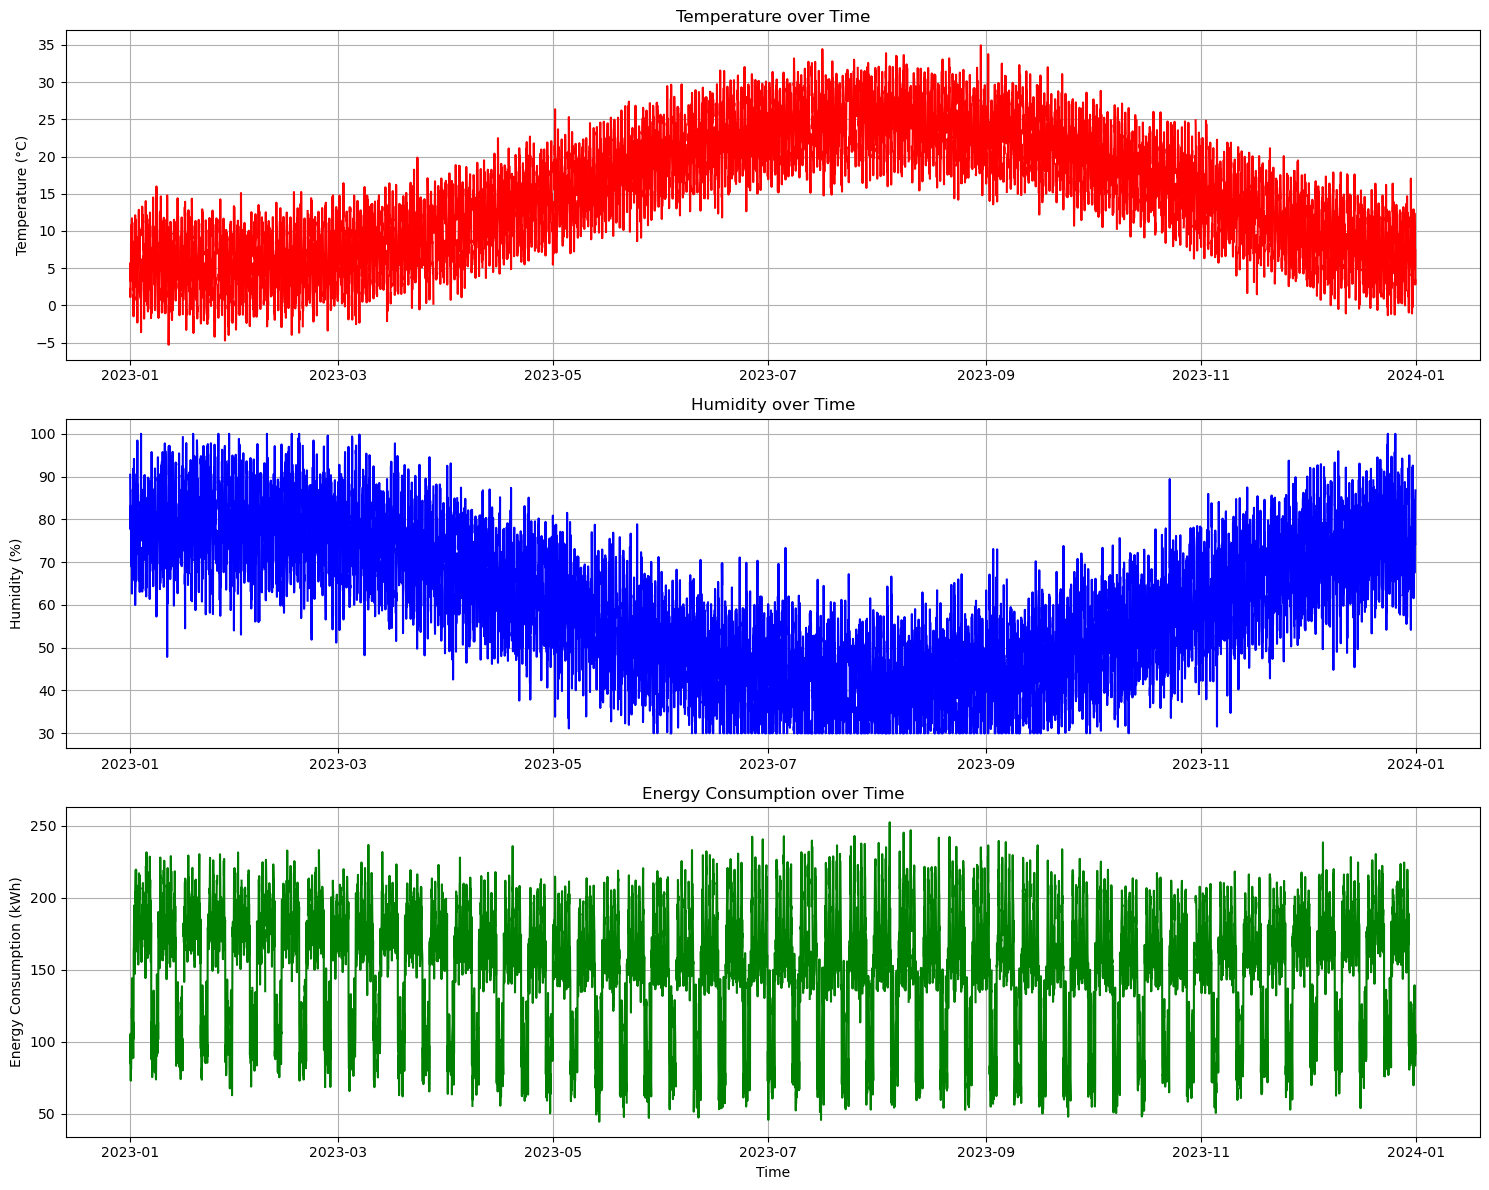

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the style for better visualization
try:
    plt.style.use('seaborn')
except:
    # Fallback to default style if seaborn style is not available
    plt.style.use('default')

# Create figure and axis with specified size
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 12))

# Plot temperature
ax1.plot(df.index, df['temperature'], color='red')
ax1.set_title('Temperature over Time')
ax1.set_ylabel('Temperature (°C)')
ax1.grid(True)

# Plot humidity
ax2.plot(df.index, df['humidity'], color='blue')
ax2.set_title('Humidity over Time')
ax2.set_ylabel('Humidity (%)')
ax2.grid(True)

# Plot energy consumption
ax3.plot(df.index, df['energy_kwh'], color='green')
ax3.set_title('Energy Consumption over Time')
ax3.set_ylabel('Energy Consumption (kWh)')
ax3.set_xlabel('Time')
ax3.grid(True)

# Adjust layout to prevent overlap
plt.tight_layout()

# Display the plot
plt.show()


## 4. Data Cleaning
Handle missing values, outliers, and inconsistencies in the data.

In [7]:
print("Missing values before cleaning:")
print(df.isnull().sum())

# Fill missing values using forward-fill
df.ffill(inplace=True)

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values before cleaning:
energy_kwh     88
temperature    88
humidity       88
dtype: int64
Missing values after cleaning:
energy_kwh     0
temperature    0
humidity       0
dtype: int64


## 4. Feature Engineering
We'll create calendar, weather, and lag features to help our models capture patterns in the data.

In [8]:
def create_features(df):
    df['hour'] = df.index.hour
    df['day_of_week'] = df.index.dayofweek
    df['month'] = df.index.month
    df['quarter'] = df.index.quarter
    df['day_of_year'] = df.index.dayofyear
    df['is_weekend'] = (df.index.dayofweek >= 5).astype(int)
    
    # Lag features for energy
    df['energy_lag_24h'] = df['energy_kwh'].shift(24)
    df['energy_lag_1w'] = df['energy_kwh'].shift(24 * 7)
    
    return df

df = create_features(df)
df.dropna(inplace=True) # Drop rows with NaNs from lag features
df.head()

,energy_kwh,temperature,humidity,hour,day_of_week,month,quarter,day_of_year,is_weekend,energy_lag_24h,energy_lag_1w
timestamp,,,,,,,,,,,
2023-01-08 00:00:00,78.761555,0.217810,84.542692,0,6,1,1,8,1,87.958576,96.775844
2023-01-08 01:00:00,93.305281,-0.628516,91.891155,1,6,1,1,8,1,111.085519,104.976086
2023-01-08 02:00:00,111.272907,-0.400570,88.969432,2,6,1,1,8,1,113.953682,85.042839
2023-01-08 03:00:00,98.356280,0.541431,89.800948,3,6,1,1,8,1,114.140077,105.493308
2023-01-08 04:00:00,105.521044,3.054382,84.002988,4,6,1,1,8,1,92.612811,73.024146


## 5. Time-Based Split & Baseline Models
We'll split our data into training and testing sets based on time. We'll also create simple baseline models to compare against.

In [9]:
split_date = '2023-10-01'
train_df = df.loc[df.index < split_date]
test_df = df.loc[df.index >= split_date]

X_train = train_df.drop('energy_kwh', axis=1)
y_train = train_df['energy_kwh']
X_test = test_df.drop('energy_kwh', axis=1)
y_test = test_df['energy_kwh']

# Baseline 1: Persistence Model (predicts the last known value)
y_pred_persist = X_test['energy_lag_24h'] # Using 24h lag as persistence

# Baseline 2: Seasonal Naive Model (predicts the value from the same time last week)
y_pred_seasonal = X_test['energy_lag_1w']

print(f"Persistence MAE: {mean_absolute_error(y_test, y_pred_persist):.2f}")
print(f"Seasonal Naive MAE: {mean_absolute_error(y_test, y_pred_seasonal):.2f}")

Persistence MAE: 30.58
Seasonal Naive MAE: 11.36


## 6. Machine Learning Models
Now, let's train OLS/Ridge and a Random Forest model.

In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# OLS/Ridge Regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)
y_pred_ridge = ridge.predict(X_test_scaled)

# Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1, max_features='sqrt')
rf.fit(X_train, y_train) # RF doesn't require scaling
y_pred_rf = rf.predict(X_test)

print(f"Ridge MAE: {mean_absolute_error(y_test, y_pred_ridge):.2f}")
print(f"Random Forest MAE: {mean_absolute_error(y_test, y_pred_rf):.2f}")

Ridge MAE: 17.80
Random Forest MAE: 9.62


## 7. Error Analysis
Let's visualize the predictions and analyze where the models are making errors.

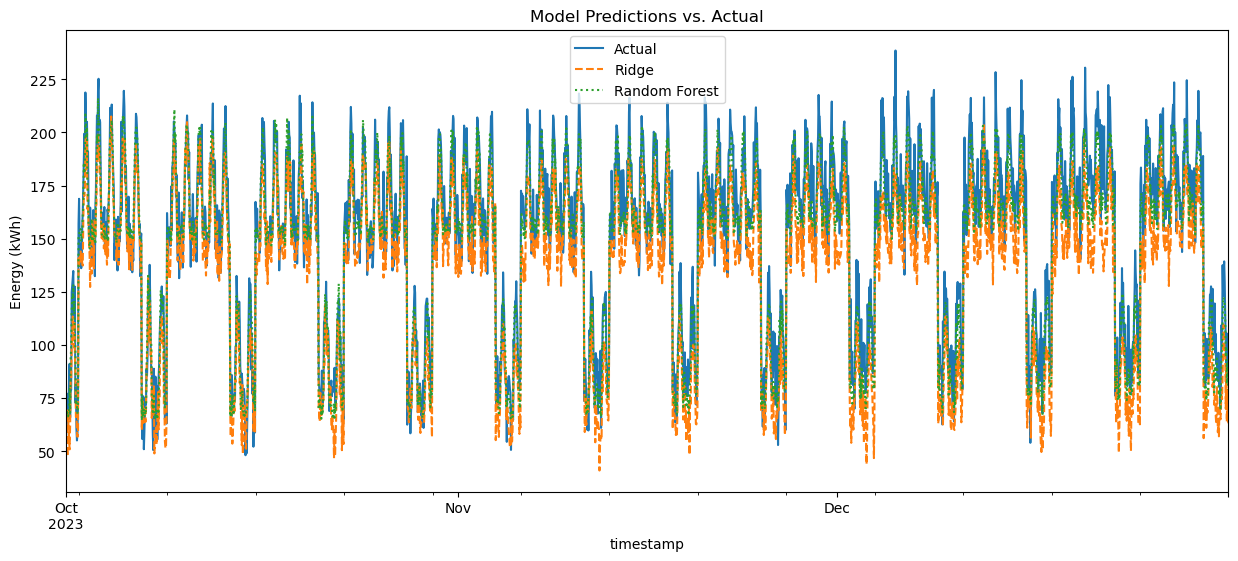

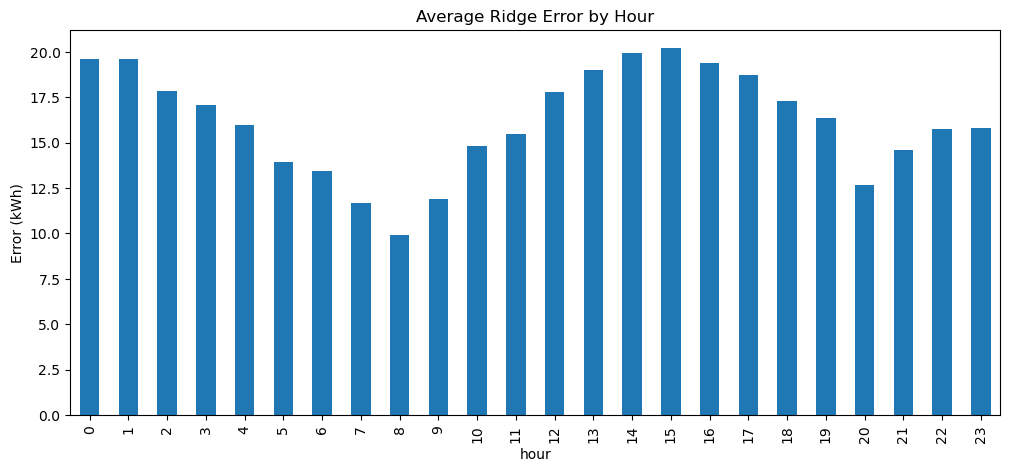

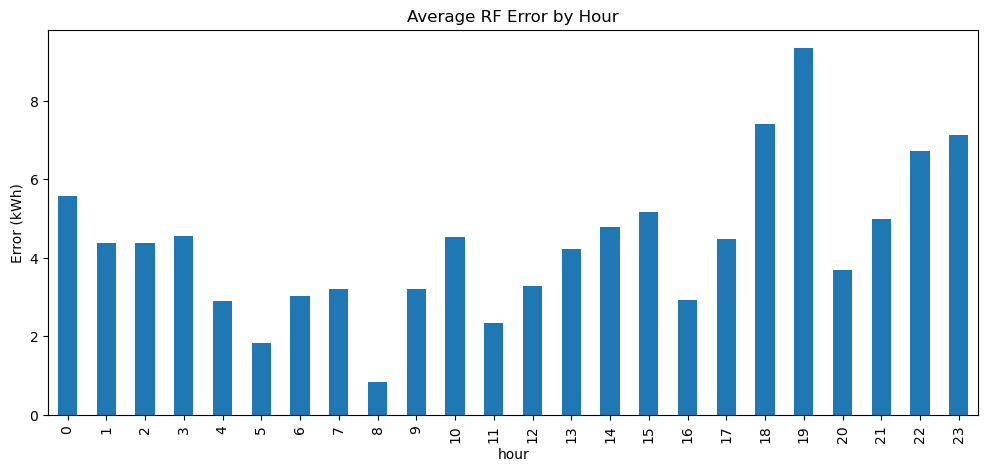

In [11]:
results = pd.DataFrame({'Actual': y_test, 'Ridge': y_pred_ridge, 'Random Forest': y_pred_rf})
results.plot(figsize=(15, 6), style=['-', '--', ':'])
plt.title('Model Predictions vs. Actual')
plt.ylabel('Energy (kWh)')
plt.show()

# Error by day of week
results['error_ridge'] = results['Actual'] - results['Ridge']
results['hour'] = results.index.hour
results.groupby('hour')['error_ridge'].mean().plot(kind='bar', figsize=(12, 5))
plt.title('Average Ridge Error by Hour')
plt.ylabel('Error (kWh)')
plt.show()

# Error by hour
results['error_rf'] = results['Actual'] - results['Random Forest']
results['hour'] = results.index.hour
results.groupby('hour')['error_rf'].mean().plot(kind='bar', figsize=(12, 5))
plt.title('Average RF Error by Hour')
plt.ylabel('Error (kWh)')
plt.show()

## 8. Interpretability with SHAP
We'll use SHAP to understand which features are most important for the Random Forest model.

/var/folders/wc/1xdjgq_x17ldscyry9fzbc180000gp/T/ipykernel_96677/3168324327.py:4: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test.head(100))


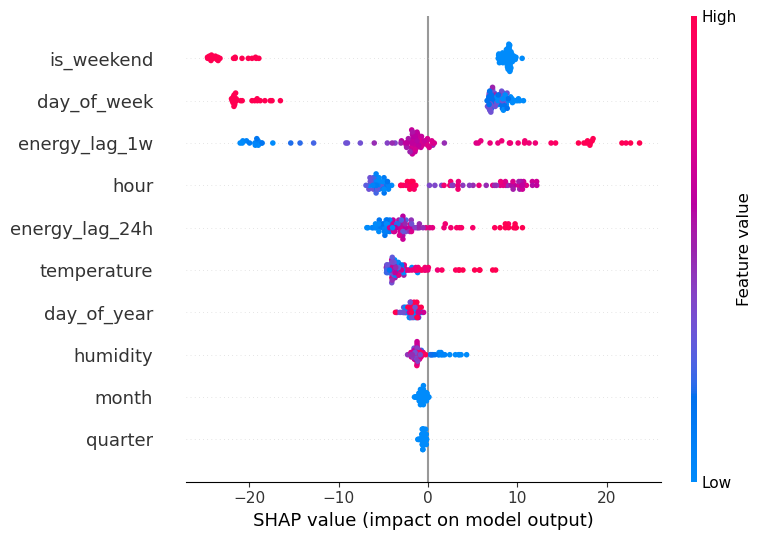

In [12]:
explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_test.head(100)) # Use a subset for speed

shap.summary_plot(shap_values, X_test.head(100))

## 9. Save Artifacts
This section is a placeholder for saving models, documentation, etc.

In [22]:
print("Experiment complete! Consider saving the model using joblib or pickle.")

Experiment complete! Consider saving the model using joblib or pickle.
